# Notebook 14 — Contextual hybrid bomb-permission screen

This development experiment asks whether contextual one-branch permission can retain most of the relaxed policy's productivity while reducing forced bomb self-traps. Strict two-branch is archived and is not a candidate. The original 1,600-round core screen is supplemented by a separately locked 1,600-round robustness extension on `rule_based` and `internal_mixed`.

**Development-set note.** This experiment uses the previously observed seeds `66001–66040` to compare the relaxed, original hybrid, phase/productive hybrid, and armed-threat hybrid variants. These results are for screening only; final conclusions require fresh seeds.

## Locked protocol

- Candidate: `dueling_hunt_center_04`; checkpoint `709cca4351f3bc5893f766b01b8c9335fa299d25331a275ae281b123df31009a`
- Conditions: `one_branch_relaxed`, `original_hybrid`, `phase_productive_hybrid`, `armed_threat_hybrid`
- Lineups: `external_mixed`, `frozen_dddqn`, `rule_based`, `internal_mixed`
- Seeds: `66001–66040`; five rounds per seed
- Workload: 3200 rounds
- Structure: 1600 core rounds + 1600 auxiliary robustness rounds
- Inference: five rounds averaged within seed, then 10,000-replicate paired bootstrap
- Status: development screen; strict two-branch archived

The enhanced pipeline records all counterfactual permissions, multi-label rejection reasons, Q margins, branch directions, phase and threat context, and bomb lifecycle outcomes.

In [9]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display
ROOT = Path('..').resolve()
payload = json.loads((ROOT/'results/e2_contextual_hybrid_screen/summary.json').read_text())
aggregate = pd.DataFrame(payload['aggregate'])
paired = pd.DataFrame(payload['paired_bootstrap'])
rejection_reasons = pd.DataFrame(payload['rejection_reason_totals'])
strict_attribution = pd.DataFrame(payload['strict_self_trap_attribution'])
pd.set_option('display.max_columns', 30)

## Completeness and pairing

All four arms must match on every initial-condition hash.

In [10]:
variants = ['one_branch_relaxed', 'original_hybrid',
            'phase_productive_hybrid', 'armed_threat_hybrid']
manifest_map = {}
for row in payload['ledger']:
    manifest_map[(row['lineup'], row['variant'], row['seed'])] = json.loads(
        (ROOT / row['manifest']).read_text()
    )
pairing_rows = []
for lineup in payload['protocol']['lineups']:
    matched = 0
    for seed in payload['protocol']['seeds']:
        hashes = [
            [item['sha256'] for item in manifest_map[(lineup, variant, seed)]['initial_conditions']]
            for variant in variants
        ]
        matched += sum(len({arm[index] for arm in hashes}) == 1 for index in range(5))
    pairing_rows.append({'lineup': lineup, 'matched_rounds': matched, 'expected': 200})
pairing_check = pd.DataFrame(pairing_rows)
display(pairing_check)

,lineup,matched_rounds,expected
0,external_mixed,200,200
1,frozen_dddqn,200,200
2,rule_based,200,200
3,internal_mixed,200,200


## Strict self-trap definition

The original `self_trapped_after_bomb` flag is retained as `raw_zero` for auditability, but it is no longer the primary safety outcome because it includes a non-actionable sample taken on the BOMB placement step.

- `post_placement_escape_collapse`: a zero-viability sample occurs at a strictly later step.
- `confirmed_catastrophic_self_trap`: post-placement escape collapse occurs and the agent subsequently dies with its own bomb causally involved (`own_bomb_suicide` or `own_and_opponent_bomb`). This conservative outcome-confirmed label is the primary self-trap metric below.

This revision re-summarises the immutable traces; it does not rerun or alter any game.


## Aggregate outcomes and strict lifecycle diagnostics

In [11]:
aggregate_columns = [
    'lineup', 'variant', 'rounds', 'score', 'coins', 'crates', 'bombs', 'kills',
    'suicides', 'survived', 'self_trapped_after_bomb',
    'post_placement_escape_collapse', 'confirmed_catastrophic_self_trap',
    'confirmed_catastrophic_self_traps_per_100_bombs', 'median_confirmed_trap_step',
    'bomb_proposals_total', 'bomb_rejections_total', 'decision_ms_p95',
]
display(aggregate[aggregate_columns].round(4))

,lineup,variant,rounds,score,coins,crates,bombs,kills,suicides,survived,self_trapped_after_bomb,post_placement_escape_collapse,confirmed_catastrophic_self_trap,confirmed_catastrophic_self_traps_per_100_bombs,median_confirmed_trap_step,bomb_proposals_total,bomb_rejections_total,decision_ms_p95
0,external_mixed,one_branch_relaxed,200,2.985,2.060,27.795,45.935,0.185,0.210,0.755,0.260,0.160,0.140,0.3048,152.0,9188,0,11.1377
1,external_mixed,original_hybrid,200,2.505,1.755,23.415,41.515,0.150,0.175,0.720,0.175,0.145,0.120,0.2891,173.0,11847,3544,14.2510
2,external_mixed,phase_productive_hybrid,200,2.490,1.765,23.625,41.665,0.145,0.175,0.725,0.175,0.145,0.120,0.2880,173.0,11811,3478,13.8450
3,external_mixed,armed_threat_hybrid,200,2.445,1.695,23.135,41.190,0.150,0.185,0.715,0.185,0.155,0.130,0.3156,153.5,11830,3592,14.2843
4,frozen_dddqn,one_branch_relaxed,200,3.895,2.245,32.920,44.535,0.330,0.260,0.665,0.510,0.425,0.230,0.5164,244.0,8907,0,14.7581
5,frozen_dddqn,original_hybrid,200,3.090,1.965,28.305,39.915,0.225,0.225,0.645,0.310,0.300,0.205,0.5136,238.0,12329,4346,14.3800
6,frozen_dddqn,phase_productive_hybrid,200,3.115,1.965,28.400,39.825,0.230,0.225,0.650,0.310,0.300,0.210,0.5273,233.5,12267,4302,13.8731
7,frozen_dddqn,armed_threat_hybrid,200,3.025,1.900,28.110,39.890,0.225,0.235,0.640,0.320,0.310,0.210,0.5264,237.0,12436,4458,13.8630
8,rule_based,one_branch_relaxed,200,4.585,3.060,32.345,40.675,0.305,0.250,0.700,0.375,0.325,0.235,0.5778,93.0,8135,0,11.1989
9,rule_based,original_hybrid,200,4.170,2.920,30.305,41.830,0.250,0.165,0.770,0.195,0.185,0.150,0.3586,116.0,10358,1991,36.7389


## Focused robustness contrasts

All entries are `one_branch_relaxed − comparator`, with paired 95% seed-bootstrap intervals. Positive score values favor relaxed; positive trap or suicide values indicate worse safety for relaxed.



In [12]:
def paired_interval(lineup, contrast, metric):
    row = paired[
        (paired.lineup == lineup) &
        (paired.contrast == contrast) &
        (paired.metric == metric)
    ].iloc[0]
    return f"{row.mean_difference:+.3f} [{row.ci_low:+.3f}, {row.ci_high:+.3f}]"

robustness_rows = []
for lineup in payload['protocol']['robustness_lineups']:
    for comparator in ['original_hybrid', 'phase_productive_hybrid', 'armed_threat_hybrid']:
        contrast = f'one_branch_relaxed-{comparator}'
        robustness_rows.append({
            'lineup': lineup,
            'contrast': contrast,
            'score Δ [95% CI]': paired_interval(lineup, contrast, 'score'),
            'confirmed trap Δ [95% CI]': paired_interval(
                lineup, contrast, 'confirmed_catastrophic_self_trap'),
            'suicide Δ [95% CI]': paired_interval(lineup, contrast, 'suicides'),
        })
robustness_effects = pd.DataFrame(robustness_rows)
display(robustness_effects)

,lineup,contrast,score Δ [95% CI],confirmed trap Δ [95% CI],suicide Δ [95% CI]
0,rule_based,one_branch_relaxed-original_hybrid,"+0.415 [-0.145, +0.980]","+0.085 [+0.025, +0.150]","+0.085 [+0.015, +0.155]"
1,rule_based,one_branch_relaxed-phase_productive_hybrid,"+0.410 [-0.130, +0.965]","+0.080 [+0.015, +0.145]","+0.075 [+0.010, +0.145]"
2,rule_based,one_branch_relaxed-armed_threat_hybrid,"+0.395 [-0.160, +0.965]","+0.095 [+0.035, +0.155]","+0.100 [+0.035, +0.165]"
3,internal_mixed,one_branch_relaxed-original_hybrid,"-0.155 [-0.650, +0.345]","+0.010 [-0.045, +0.065]","+0.015 [-0.045, +0.075]"
4,internal_mixed,one_branch_relaxed-phase_productive_hybrid,"-0.050 [-0.510, +0.415]","-0.005 [-0.065, +0.050]","-0.010 [-0.070, +0.050]"
5,internal_mixed,one_branch_relaxed-armed_threat_hybrid,"+0.110 [-0.415, +0.635]","-0.025 [-0.085, +0.035]","-0.015 [-0.080, +0.050]"


### Robustness interpretation

The robustness result is context-dependent. Against three rule-based opponents, relaxed has higher point-estimate score but its interval overlaps zero, while confirmed catastrophic self-traps and suicides are clearly higher than under every hybrid. This is not merely reduced bomb exposure: original hybrid placed 8,366 bombs versus relaxed's 8,135, yet confirmed traps fell from 47 to 30 (0.578 to 0.359 per 100 bombs). Moreover, 45/47 relaxed confirmed traps occurred during crate economy, with median placement step 91, indicating early self-generated bombing risk rather than opponent-driven hunt pressure. Against `internal_mixed`, neither score nor strict-safety contrasts are resolved. Thus the hybrid safety effect is real in the rule-based lineup but does not generalise uniformly across opponent pools; none of the two new hybrids establishes a Pareto improvement over the original hybrid.


## Strict self-trap attribution

`confirmed_death_latency_median` is measured from the first post-placement zero-viability step to death. Scores are official game scores at bomb placement. The final column is the share of confirmed catastrophic self-traps after which no further official score was gained.


In [13]:
attribution_columns = [
    'lineup', 'variant', 'actual_bombs_total', 'raw_zero_total',
    'same_step_only_zero_total', 'post_placement_escape_collapse_total',
    'confirmed_catastrophic_self_trap_total', 'confirmed_crate_economy_total',
    'confirmed_hunt_total', 'confirmed_placement_step_median',
    'confirmed_death_latency_median', 'score_at_placement_mean',
    'score_at_placement_median', 'no_score_gain_after_confirmed_rate',
]
display(strict_attribution[attribution_columns].round(4))

,lineup,variant,actual_bombs_total,raw_zero_total,same_step_only_zero_total,post_placement_escape_collapse_total,confirmed_catastrophic_self_trap_total,confirmed_crate_economy_total,confirmed_hunt_total,confirmed_placement_step_median,confirmed_death_latency_median,score_at_placement_mean,score_at_placement_median,no_score_gain_after_confirmed_rate
0,external_mixed,one_branch_relaxed,9187,52,20,32,28,23,5,149.5,3.0,2.2143,2.0,0.9286
1,external_mixed,original_hybrid,8303,35,6,29,24,14,10,170.0,2.0,2.2917,2.0,1.0000
2,external_mixed,phase_productive_hybrid,8333,35,6,29,24,14,10,170.0,2.0,2.2500,2.0,1.0000
3,external_mixed,armed_threat_hybrid,8238,37,6,31,26,17,9,151.5,2.0,1.8846,1.5,1.0000
4,frozen_dddqn,one_branch_relaxed,8907,102,17,85,46,12,34,241.0,2.0,3.2826,2.5,1.0000
5,frozen_dddqn,original_hybrid,7983,62,2,60,41,11,30,236.0,2.0,2.1951,2.0,1.0000
6,frozen_dddqn,phase_productive_hybrid,7965,62,2,60,42,11,31,231.5,2.0,2.2143,1.5,1.0000
7,frozen_dddqn,armed_threat_hybrid,7978,64,2,62,42,11,31,234.5,2.0,2.1667,1.5,1.0000
8,rule_based,one_branch_relaxed,8135,75,10,65,47,45,2,91.0,2.0,2.7021,2.0,0.9787
9,rule_based,original_hybrid,8366,39,2,37,30,26,4,114.0,2.0,3.2000,3.0,0.9667


## Rejection attribution

Reasons are multi-label: one rejected proposal can contribute to several columns. Counts therefore need not sum to total rejections. `—` means the contextual flag is not an operative gate for that variant.


In [14]:
reason_columns = [
    'reject_no_escape_branch', 'reject_nonproductive', 'reject_no_crates_remaining',
    'reject_step_cutoff', 'reject_active_bomb', 'reject_active_explosion',
    'reject_near_any_opponent', 'reject_near_armed_opponent',
    'reject_predicted_branch_threat',
]
operative = {
    'one_branch_relaxed': {'reject_no_escape_branch'},
    'original_hybrid': {'reject_no_escape_branch', 'reject_nonproductive',
        'reject_step_cutoff', 'reject_active_bomb', 'reject_active_explosion',
        'reject_near_any_opponent'},
    'phase_productive_hybrid': {'reject_no_escape_branch', 'reject_nonproductive',
        'reject_no_crates_remaining', 'reject_active_bomb', 'reject_active_explosion',
        'reject_near_any_opponent'},
    'armed_threat_hybrid': {'reject_no_escape_branch', 'reject_nonproductive',
        'reject_step_cutoff', 'reject_active_bomb', 'reject_active_explosion',
        'reject_near_armed_opponent', 'reject_predicted_branch_threat'},
}
rejection_display = rejection_reasons.copy()
for index, row in rejection_display.iterrows():
    for column in reason_columns:
        if column not in operative[row.variant]:
            rejection_display.loc[index, column] = pd.NA
display(rejection_display[['lineup', 'variant', *reason_columns]])

,lineup,variant,reject_no_escape_branch,reject_nonproductive,reject_no_crates_remaining,reject_step_cutoff,reject_active_bomb,reject_active_explosion,reject_near_any_opponent,reject_near_armed_opponent,reject_predicted_branch_threat
0,external_mixed,one_branch_relaxed,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,external_mixed,original_hybrid,0,670.0,NaN,559.0,2651.0,1053.0,720.0,NaN,NaN
2,external_mixed,phase_productive_hybrid,0,662.0,298.0,NaN,2648.0,1055.0,728.0,NaN,NaN
3,external_mixed,armed_threat_hybrid,0,674.0,NaN,558.0,2687.0,1070.0,NaN,661.0,503.0
4,frozen_dddqn,one_branch_relaxed,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,frozen_dddqn,original_hybrid,0,1301.0,NaN,1364.0,3213.0,1176.0,1579.0,NaN,NaN
6,frozen_dddqn,phase_productive_hybrid,0,1286.0,964.0,NaN,3192.0,1170.0,1567.0,NaN,NaN
7,frozen_dddqn,armed_threat_hybrid,0,1286.0,NaN,1349.0,3297.0,1197.0,NaN,1224.0,881.0
8,rule_based,one_branch_relaxed,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,rule_based,original_hybrid,0,610.0,NaN,558.0,1314.0,697.0,798.0,NaN,NaN


## All pairwise paired-bootstrap intervals

Every contrast is `left − right`. Positive values favor the left arm for score/productivity/survival; negative values favor it for suicide and self-trap metrics. `confirmed_catastrophic_self_trap` is the primary safety contrast; broader zero-viability signals are diagnostic only.


In [15]:
main_inference_metrics = [
    'score', 'bombs', 'crates', 'suicides', 'survived',
    'post_placement_escape_collapse', 'confirmed_catastrophic_self_trap',
]
paired_main = paired[paired.metric.isin(main_inference_metrics)][[
    'lineup', 'contrast', 'metric', 'mean_difference', 'ci_low', 'ci_high',
    'positive_seeds', 'zero_seeds', 'negative_seeds', 'paired_seeds',
]].copy()
with pd.option_context('display.max_rows', None):
    display(paired_main.round(4))

,lineup,contrast,metric,mean_difference,ci_low,ci_high,positive_seeds,zero_seeds,negative_seeds,paired_seeds
0,external_mixed,one_branch_relaxed-original_hybrid,score,0.480,0.0800,0.8800,27,2,11,40
2,external_mixed,one_branch_relaxed-original_hybrid,crates,4.380,3.3700,5.4350,37,0,3,40
3,external_mixed,one_branch_relaxed-original_hybrid,bombs,4.420,1.2600,7.6250,26,0,14,40
5,external_mixed,one_branch_relaxed-original_hybrid,suicides,0.035,-0.0350,0.1100,16,11,13,40
6,external_mixed,one_branch_relaxed-original_hybrid,survived,0.035,-0.0600,0.1250,19,7,14,40
11,external_mixed,one_branch_relaxed-original_hybrid,post_placement_escape_collapse,0.015,-0.0550,0.0900,13,16,11,40
12,external_mixed,one_branch_relaxed-original_hybrid,confirmed_catastrophic_self_trap,0.020,-0.0400,0.0850,13,18,9,40
21,external_mixed,one_branch_relaxed-phase_productive_hybrid,score,0.495,0.1050,0.8750,28,2,10,40
23,external_mixed,one_branch_relaxed-phase_productive_hybrid,crates,4.170,3.1750,5.2550,37,0,3,40
24,external_mixed,one_branch_relaxed-phase_productive_hybrid,bombs,4.270,1.2100,7.4000,26,0,14,40


## Development decision

This is a development-screen conclusion, not fresh confirmation.

- `phase_productive_hybrid` vs original score Δ: external_mixed -0.015 [-0.105, +0.070]; frozen_dddqn +0.025 [-0.000, +0.075]; rule_based +0.005 [-0.105, +0.120]; internal_mixed -0.105 [-0.405, +0.185]. vs relaxed confirmed catastrophic self-trap Δ: external_mixed -0.020 [-0.080, +0.040]; frozen_dddqn -0.020 [-0.110, +0.070]; rule_based -0.080 [-0.145, -0.015]; internal_mixed +0.005 [-0.050, +0.065].
- `armed_threat_hybrid` vs original score Δ: external_mixed -0.060 [-0.180, +0.040]; frozen_dddqn -0.065 [-0.180, +0.045]; rule_based +0.020 [-0.100, +0.145]; internal_mixed -0.265 [-0.600, +0.080]. vs relaxed confirmed catastrophic self-trap Δ: external_mixed -0.010 [-0.070, +0.045]; frozen_dddqn -0.020 [-0.100, +0.060]; rule_based -0.095 [-0.155, -0.035]; internal_mixed +0.025 [-0.035, +0.085].

No new candidate clears the pre-specified score-improvement requirement, so neither advances to fresh-seed confirmation. `one_branch_relaxed` remains the score-optimal baseline. Under the strict outcome-confirmed metric, `original_hybrid` does not show a general catastrophic-self-trap advantage over relaxed across all lineups. A measurable advantage appears only in `rule_based`; the rule should therefore be described as a context-dependent conservative policy, not a universally established safety compromise.

Only a candidate that improves the original hybrid without a clear outcome-safety regression, while retaining a measurable direct-safety advantage over relaxed, may advance. At most one candidate should be taken to fresh seeds.

## Reproduction and provenance

```bash
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e2_contextual_hybrid_screen.py status
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e2_contextual_hybrid_screen.py summarize
```

Raw stats, version-2 traces, manifests, hashes, seed rows and bootstrap results are stored under `results/e2_contextual_hybrid_screen/`.

## Figure 6 — Core productivity–safety trade-off

The following cell is the complete plotting code used for Figure 6. It reads the stored seed-level paired-bootstrap results, regenerates both publication files, and displays the figure inline.


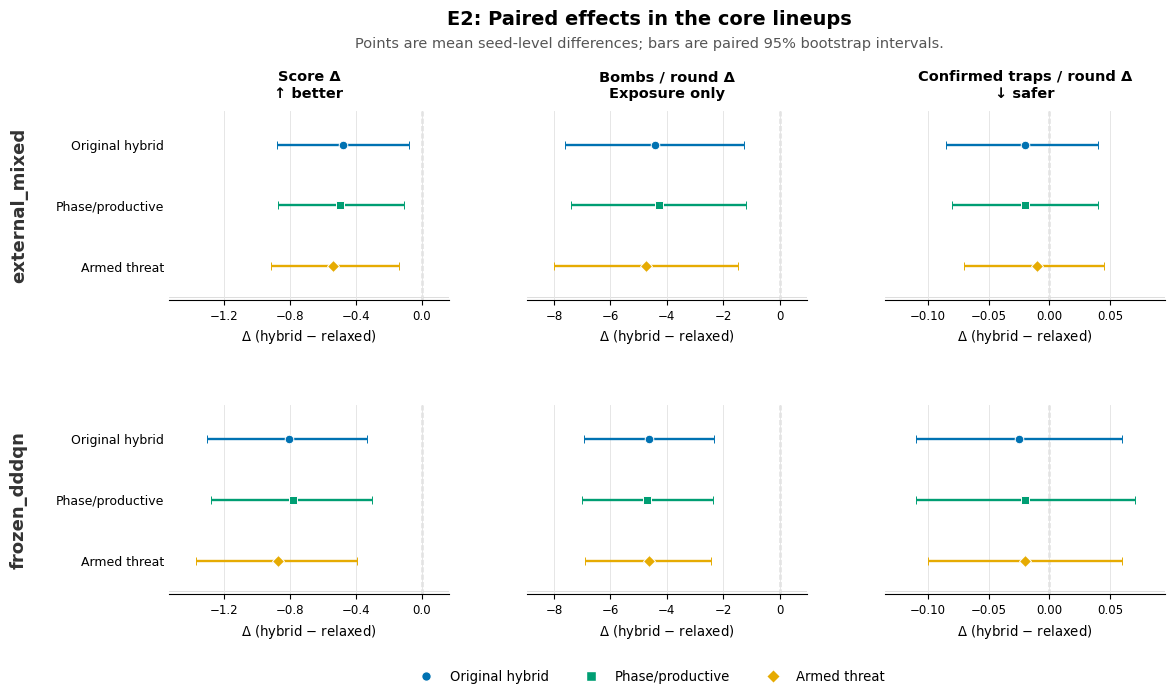

In [29]:
# Reproduce Figure 6 directly from the E2 paired-bootstrap results.
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

project_root = Path('..').resolve()
summary_path = project_root / 'results/e2_contextual_hybrid_screen/summary.json'
figure_png = project_root / 'results/e2_contextual_hybrid_screen/figure6_e2_core_paired_effects.png'
figure_pdf = project_root / 'results/e2_contextual_hybrid_screen/figure6_e2_core_paired_effects.pdf'
e2 = json.loads(summary_path.read_text())

core_lineups = ('external_mixed', 'frozen_dddqn')
hybrids = (
    ('original_hybrid', 'Original hybrid', 'o', '#0072B2'),
    ('phase_productive_hybrid', 'Phase/productive', 's', '#009E73'),
    ('armed_threat_hybrid', 'Armed threat', 'D', '#E6AB02'),
)
metrics = (
    ('score', 'Score Δ', '↑ better'),
    ('bombs', 'Bombs / round Δ', 'Exposure only'),
    ('confirmed_catastrophic_self_trap',
     'Confirmed traps / round Δ', '↓ safer'),
)

def hybrid_minus_relaxed(lineup, hybrid, metric):
    """Invert the stored relaxed-minus-hybrid contrast."""
    contrast = f'one_branch_relaxed-{hybrid}'
    row = next(
        item for item in e2['paired_bootstrap']
        if item['lineup'] == lineup
        and item['contrast'] == contrast
        and item['metric'] == metric
    )
    return -row['mean_difference'], -row['ci_high'], -row['ci_low']

def shared_limits(metric):
    values = [0.0]
    for lineup in core_lineups:
        for hybrid, *_ in hybrids:
            values.extend(hybrid_minus_relaxed(lineup, hybrid, metric))
    span = max(values) - min(values)
    padding = max(
        span * 0.12,
        0.025 if metric == 'confirmed_catastrophic_self_trap' else 0.1,
    )
    return min(values) - padding, max(values) + padding

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5,
    'axes.titlesize': 10.5, 'axes.labelsize': 9.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 9.0,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=False)
y_positions = list(range(len(hybrids)))[::-1]
x_limits = {metric: shared_limits(metric) for metric, *_ in metrics}

for row_index, lineup in enumerate(core_lineups):
    for column_index, (metric, title, direction) in enumerate(metrics):
        ax = axes[row_index, column_index]
        ax.axvline(0, color='#8A8A8A', linewidth=1.0, linestyle='--', zorder=0)
        ax.axhline(-0.5, color='#D8D8D8', linewidth=0.6, zorder=0)
        for y, (hybrid, label, marker, color) in zip(y_positions, hybrids):
            estimate, low, high = hybrid_minus_relaxed(lineup, hybrid, metric)
            ax.errorbar(
                estimate, y,
                xerr=[[estimate - low], [high - estimate]],
                fmt=marker, markersize=6.2,
                markerfacecolor=color, markeredgecolor='white', markeredgewidth=0.7,
                ecolor=color, elinewidth=1.7, capsize=3.0, capthick=1.2, zorder=3,
            )
        ax.set_xlim(*x_limits[metric])
        ax.set_ylim(-0.55, len(hybrids) - 0.45)
        ax.set_yticks(y_positions)
        if column_index == 0:
            ax.set_yticklabels([item[1] for item in hybrids])
        else:
            ax.set_yticklabels([])
            ax.tick_params(axis='y', length=0)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.grid(axis='x', color='#E6E6E6', linewidth=0.7, zorder=0)
        ax.spines[['top', 'right', 'left']].set_visible(False)
        ax.tick_params(axis='y', length=0)
        ax.set_xlabel(r'$\Delta$ (hybrid $-$ relaxed)')
        if row_index == 0:
            ax.set_title(f'{title}\n{direction}', pad=10, fontweight='semibold')

legend_handles = [
    Line2D([0], [0], marker=marker, color=color, label=label, linestyle='none',
           markerfacecolor=color, markeredgecolor='white', markersize=7)
    for _, label, marker, color in hybrids
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, frameon=False,
           bbox_to_anchor=(0.55, 0.005), columnspacing=2.2)
fig.suptitle('E2: Paired effects in the core lineups',
             x=0.55, y=0.985, fontsize=14, fontweight='bold')
fig.text(0.55, 0.947,
         'Points are mean seed-level differences; bars are paired 95% bootstrap intervals.',
         ha='center', va='top', fontsize=10.5, color='#555555')
fig.subplots_adjust(left=0.15, right=0.98, top=0.84, bottom=0.15,
                    wspace=0.28, hspace=0.56)
for row_index, lineup in enumerate(core_lineups):
    box = axes[row_index, 0].get_position()
    fig.text(0.025, (box.y0 + box.y1) / 2, lineup, rotation=90,
             va='center', ha='center', fontsize=13,
             fontweight='bold', color='#333333')

fig.savefig(figure_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(figure_pdf, bbox_inches='tight', facecolor='white')
plt.show()


**Figure 6.** Paired effects of contextual bomb-permission rules relative to `one_branch_relaxed` in the two core lineups. Points denote mean seed-level differences and horizontal bars show paired 95% bootstrap intervals. Positive score differences favour the hybrid rule, whereas negative self-trap differences indicate fewer confirmed catastrophic self-traps. Differences in executed bombs indicate exposure changes and are not themselves a performance objective.

Vector version: [PDF](../results/e2_contextual_hybrid_screen/figure6_e2_core_paired_effects.pdf).
